# Testing objective function

In [1]:
import sys
sys.path.insert(0, "../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [3]:
z_slice_mosh = 25
bins_mosh = 85
dose_grid_half_mosh = 2.5
lattice_mosh = dose_grid_half_mosh*2/bins_mosh
source_transZ_mosh = -0.5
source_plane_mosh = cm_to_voxel(np.array(source_transZ_mosh), bins_mosh, dose_grid_half_mosh*2/bins_mosh)

In [4]:
# Common parameters
norm_point = (0.0, 0.3)
applicator_rad = 0.3
source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-2.5, 2.5)
rngY = (-2.5, 2.5)

In [5]:
def randomize_distribution(energy):
    shape = np.shape(energy)
    max = np.max(energy)
    min = np.min(energy)
    offset = (max - min)*np.random.random_sample(shape) + min
    return energy + offset

def random_by_point(energy):
    rand = np.empty(np.shape(energy))
    it = np.nditer(energy, flags=['multi_index'])
    for x in it:
        b = x + x/2
        a = x - x/2
        offset = (b - a)*np.random.rand() + a
        rand[it.multi_index] = offset
    return rand

In [6]:
mosh = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_10_5rod_6rod/5rods_12oclock_open_1e7_85bins_2.5cmHL.csv"

norm_energy, __ = extract_norm_energy(mosh, source_plane_mosh, 2, norm_point, bins_mosh, lattice_mosh)

Xm, Ym, energym, __ = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane_mosh, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=False, norm_energy=norm_energy, zero_source=True, std_dev=False)

In [7]:
# Extract energy at constant radius
error = 0.025 # cm - extracting energy from voxels
delta = 0.05 # cm - offset from applicator edge
theta = pi/2

lin_mosh, const_rad_mosh = energy_along_theta(mosh, theta, (bins_mosh, bins_mosh), dose_grid_half_mosh, z_slice_mosh, err=error, radius=applicator_rad + delta)

In [8]:
# Sanity check - plot energy at constant radius
thetam, ym, std_dev_sum_theta_m, __, __ = plotter_1D(const_rad_mosh, ind_var=1, std_dev=True, num_Hx=1e7)

<ErrorbarContainer object of 3 artists>

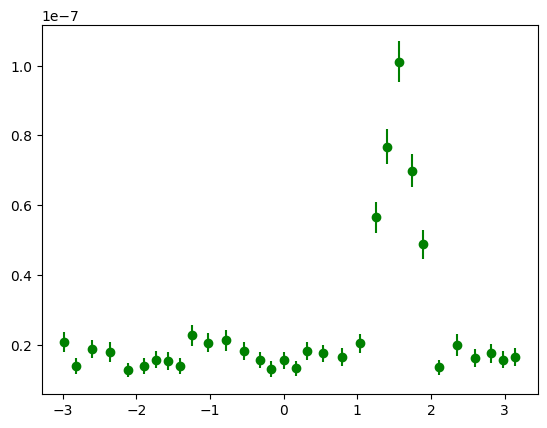

In [9]:
fig1, ax1 = plt.subplots()
ax1.errorbar(thetam, ym, yerr=std_dev_sum_theta_m, fmt="go")

In [10]:
# Sanity check - plot energy at constant radius with random offset
#rand_mosh = randomize_distribution(ym)
rand_mosh = random_by_point(ym)

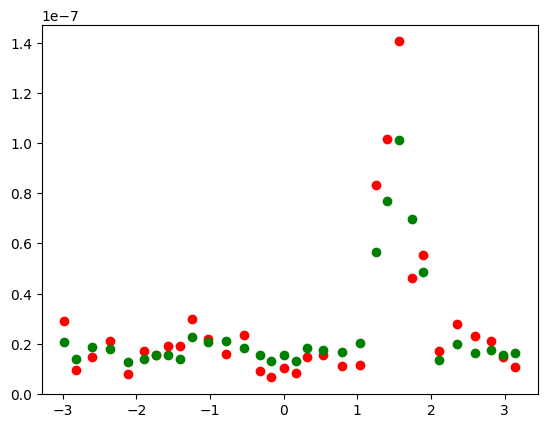

In [11]:
fig2, ax2 = plt.subplots()
ax2.scatter(thetam, rand_mosh, color="red")
ax2.scatter(thetam, ym, color="green")

### Defining objective function

Initial objective function:
$$ f(E, E') = \left [1 - \log{\left ( \sum_{i} | E_i - E'_{i} |^2 \right )} \right ]^{-1} $$

In [19]:
def naive_objective(energy1, energy2):
    diff = energy1 - energy2
    return np.sum(np.abs(diff)**2)

def logistics_obj(energy1, energy2):
    diff = np.sum(np.abs(energy1 - energy2)**2)
    return 1/(1 + np.exp(-1*diff))

def log_obj(energy1, energy2):
    diff = np.sum(np.abs(energy1 - energy2)**2)
    return 1/(1 - np.log(diff))

In [20]:
# Testing objective function on randomized sample above
obj1 = naive_objective(rand_mosh, ym)
print(obj1) 
obj2 = logistics_obj(rand_mosh, ym)
print(obj2)
obj3 = log_obj(rand_mosh, ym)
print(obj3)

4.196527238904224e-15
0.5000000000000011
0.02932162738476169


In [23]:
# Comparing objective function on randomization by point vs randomization by distribution
rand_by_point_mosh = randomize_distribution(ym)

print(obj3)
obj4 = log_obj(rand_by_point_mosh, ym)
print(obj4) # larger b/c randomized distribution has a wider gap from truth than randomized by point

0.02932162738476169
0.032838437240196076
